In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
df = pd.read_csv(
    "archive/combined_data_1.txt",
    names=["user_id", "rating", "date"],
    nrows=1_000_000
)

df.head()

,user_id,rating,date
0,1:,NaN,NaN
1,1488844,3.0,2005-09-06
2,822109,5.0,2005-05-13
3,885013,4.0,2005-10-19
4,30878,4.0,2005-12-26


In [6]:
# Identify movie headers
movie_rows = df["user_id"].str.endswith(":")

# Extract movie IDs and forward-fill them
df["movie_id"] = pd.to_numeric(
    df["user_id"].where(movie_rows).str.rstrip(":"),
    errors="coerce"
).ffill()

# Remove movie header rows
df = df[~movie_rows].copy()

# Convert data types
df["user_id"] = df["user_id"].astype(int)
df["movie_id"] = df["movie_id"].astype(int)
df["rating"] = df["rating"].astype(int)

df = df[["user_id", "movie_id", "rating", "date"]]

df.head()

,user_id,movie_id,rating,date
1,1488844,1,3,2005-09-06
2,822109,1,5,2005-05-13
3,885013,1,4,2005-10-19
4,30878,1,4,2005-12-26
5,823519,1,3,2004-05-03


In [7]:
print("Shape:", df.shape)
print("Users:", df["user_id"].nunique())
print("Movies:", df["movie_id"].nunique())

df.info()
df.describe()

Shape: (999775, 4)
Users: 283670
Movies: 225
<class 'pandas.DataFrame'>
Index: 999775 entries, 1 to 999999
Data columns (total 4 columns):
 #   Column    Non-Null Count   Dtype
---  ------    --------------   -----
 0   user_id   999775 non-null  int64
 1   movie_id  999775 non-null  int64
 2   rating    999775 non-null  int64
 3   date      999775 non-null  str  
dtypes: int64(3), str(1)
memory usage: 38.1 MB


,user_id,movie_id,rating
count,9.997750e+05,999775.000000,999775.000000
mean,1.322790e+06,126.822564,3.624417
std,7.647257e+05,69.201520,1.074986
min,6.000000e+00,1.000000,1.000000
25%,6.608210e+05,52.000000,3.000000
50%,1.319241e+06,148.000000,4.000000
75%,1.985310e+06,191.000000,4.000000
max,2.649429e+06,225.000000,5.000000


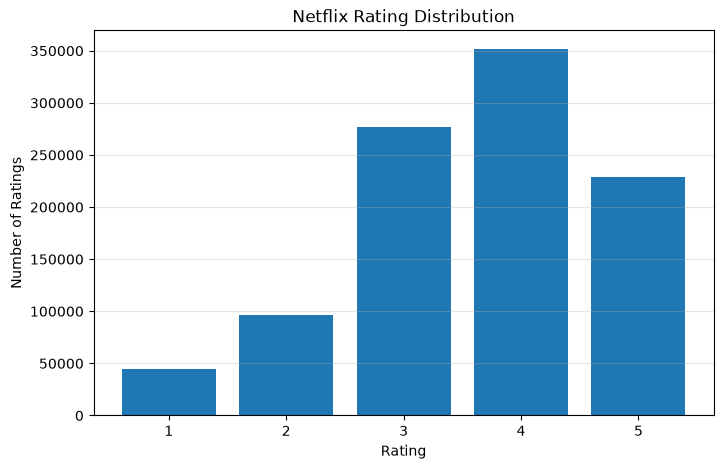

In [8]:
rating_counts = df["rating"].value_counts().sort_index()

plt.figure(figsize=(8, 5))
plt.bar(rating_counts.index, rating_counts.values)

plt.title("Netflix Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")
plt.xticks([1, 2, 3, 4, 5])
plt.grid(axis="y", alpha=0.3)

plt.show()

In [9]:
user_counts = df["user_id"].value_counts()
movie_counts = df["movie_id"].value_counts()

print("Ratings per user:")
print(user_counts.describe())

print("\nRatings per movie:")
print(movie_counts.describe())

Ratings per user:
count    283670.000000
mean          3.524430
std           3.703998
min           1.000000
25%           1.000000
50%           2.000000
75%           4.000000
max         220.000000
Name: count, dtype: float64

Ratings per movie:
count       225.000000
mean       4443.444444
std       14046.207814
min          62.000000
25%         193.000000
50%         488.000000
75%        2297.000000
max      118413.000000
Name: count, dtype: float64


In [10]:
# Remove duplicate interactions
df = df.drop_duplicates(
    subset=["user_id", "movie_id"]
).copy()

# Filter users
user_counts = df["user_id"].value_counts()

df = df[
    df["user_id"].isin(
        user_counts[user_counts >= 5].index
    )
].copy()

# Filter movies
movie_counts = df["movie_id"].value_counts()

df = df[
    df["movie_id"].isin(
        movie_counts[movie_counts >= 10].index
    )
].copy()

# Recheck users after filtering movies
user_counts = df["user_id"].value_counts()

df = df[
    df["user_id"].isin(
        user_counts[user_counts >= 5].index
    )
].copy()

print("Dataset shape:", df.shape)
print("Users:", df["user_id"].nunique())
print("Movies:", df["movie_id"].nunique())

Dataset shape: (577928, 4)
Users: 70168
Movies: 225


In [11]:
df["user_idx"], unique_users = pd.factorize(df["user_id"])
df["movie_idx"], unique_movies = pd.factorize(df["movie_id"])

num_users = len(unique_users)
num_movies = len(unique_movies)

print("Encoded users:", num_users)
print("Encoded movies:", num_movies)

df.head()

Encoded users: 70168
Encoded movies: 225


,user_id,movie_id,rating,date,user_idx,movie_idx
1,1488844,1,3,2005-09-06,0,0
3,885013,1,4,2005-10-19,1,0
4,30878,1,4,2005-12-26,2,0
5,823519,1,3,2004-05-03,3,0
6,893988,1,3,2005-11-17,4,0


In [12]:
# Choose one rating from each user for validation
val_df = df.groupby("user_idx").sample(
    n=1,
    random_state=42
)

train_df = df.drop(val_df.index).copy()

# Only evaluate movies present in training
known_movies = set(train_df["movie_idx"])

val_df = val_df[
    val_df["movie_idx"].isin(known_movies)
].copy()

print("Training ratings:", len(train_df))
print("Validation ratings:", len(val_df))

Training ratings: 507760
Validation ratings: 70168


In [13]:
X_train = [
    train_df["user_idx"].to_numpy(),
    train_df["movie_idx"].to_numpy()
]

X_val = [
    val_df["user_idx"].to_numpy(),
    val_df["movie_idx"].to_numpy()
]

y_train = train_df["rating"].to_numpy(dtype="float32")
y_val = val_df["rating"].to_numpy(dtype="float32")

print("Training labels:", y_train.shape)
print("Validation labels:", y_val.shape)

Training labels: (507760,)
Validation labels: (70168,)


In [14]:
import tensorflow as tf

from tensorflow.keras import layers, Model
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.regularizers import l2

from sklearn.metrics import mean_squared_error, mean_absolute_error

np.random.seed(42)
tf.random.set_seed(42)

X_train = {
    "user": train_df["user_idx"].to_numpy(dtype="int32").reshape(-1, 1),
    "movie": train_df["movie_idx"].to_numpy(dtype="int32").reshape(-1, 1)
}

X_val = {
    "user": val_df["user_idx"].to_numpy(dtype="int32").reshape(-1, 1),
    "movie": val_df["movie_idx"].to_numpy(dtype="int32").reshape(-1, 1)
}

rating_mean = train_df["rating"].mean()

y_train = train_df["rating"].to_numpy(dtype="float32") - rating_mean
y_val = val_df["rating"].to_numpy(dtype="float32") - rating_mean

print("Users:", num_users)
print("Movies:", num_movies)
print("Training ratings:", len(y_train))
print("Validation ratings:", len(y_val))
print("Average training rating:", rating_mean)

Users: 70168
Movies: 225
Training ratings: 507760
Validation ratings: 70168
Average training rating: 3.544361509374508


In [15]:
def build_mf_model(num_users, num_movies, embedding_dim=32):

    user_input = layers.Input(shape=(1,), name="user")
    movie_input = layers.Input(shape=(1,), name="movie")

    user_embedding = layers.Embedding(
        input_dim=num_users,
        output_dim=embedding_dim,
        embeddings_initializer="he_normal",
        embeddings_regularizer=l2(1e-6)
    )(user_input)

    movie_embedding = layers.Embedding(
        input_dim=num_movies,
        output_dim=embedding_dim,
        embeddings_initializer="he_normal",
        embeddings_regularizer=l2(1e-6)
    )(movie_input)

    user_vector = layers.Flatten()(user_embedding)
    movie_vector = layers.Flatten()(movie_embedding)

    interaction = layers.Dot(axes=1)([
        user_vector,
        movie_vector
    ])

    user_bias = layers.Flatten()(
        layers.Embedding(num_users, 1)(user_input)
    )

    movie_bias = layers.Flatten()(
        layers.Embedding(num_movies, 1)(movie_input)
    )

    output = layers.Add()([
        interaction,
        user_bias,
        movie_bias
    ])

    model = Model(
        inputs={"user": user_input, "movie": movie_input},
        outputs=output
    )

    return model


mf_model = build_mf_model(num_users, num_movies)

mf_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.003),
    loss="mse",
    metrics=[tf.keras.metrics.RootMeanSquaredError(name="rmse")]
)

mf_model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ user (InputLayer)   │ (None, 1)         │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ movie (InputLayer)  │ (None, 1)         │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 1, 32)     │  2,245,376 │ user[0][0]        │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_1         │ (None, 1, 32)     │      7,200 │ movie[0][0]       │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 32)        │          0 │ embedding[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 32)        │          0 │ embedding_1[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_2         │ (None, 1, 1)      │     70,168 │ user[0][0]        │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_3         │ (None, 1, 1)      │        225 │ movie[0][0]       │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dot (Dot)           │ (None, 1)         │          0 │ flatten[0][0],    │
│                     │                   │            │ flatten_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_2 (Flatten) │ (None, 1)         │          0 │ embedding_2[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_3 (Flatten) │ (None, 1)         │          0 │ embedding_3[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 1)         │          0 │ dot[0][0],        │
│                     │                   │            │ flatten_2[0][0],  │
│                     │                   │            │ flatten_3[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,322,969 (8.86 MB)

 Trainable params: 2,322,969 (8.86 MB)

 Non-trainable params: 0 (0.00 B)

In [16]:
early_stop_mf = EarlyStopping(
    monitor="val_loss",
    patience=3,
    mode="min",
    restore_best_weights=True
)

history_mf = mf_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=15,
    batch_size=1024,
    callbacks=[early_stop_mf],
    verbose=1
)

Epoch 1/15
496/496 ━━━━━━━━━━━━━━━━━━━━ 13s 24ms/step - loss: 0.9880 - rmse: 0.9921 - val_loss: 0.8983 - val_rmse: 0.9431
Epoch 2/15
496/496 ━━━━━━━━━━━━━━━━━━━━ 31s 45ms/step - loss: 0.6420 - rmse: 0.7903 - val_loss: 0.9753 - val_rmse: 0.9744
Epoch 3/15
496/496 ━━━━━━━━━━━━━━━━━━━━ 29s 58ms/step - loss: 0.2498 - rmse: 0.4703 - val_loss: 0.9863 - val_rmse: 0.9778
Epoch 4/15
496/496 ━━━━━━━━━━━━━━━━━━━━ 24s 23ms/step - loss: 0.1380 - rmse: 0.3266 - val_loss: 1.0006 - val_rmse: 0.9839


In [17]:
def build_ncf_model(num_users, num_movies, embedding_dim=32):

    user_input = layers.Input(shape=(1,), name="user")
    movie_input = layers.Input(shape=(1,), name="movie")

    user_embedding = layers.Embedding(
        num_users,
        embedding_dim,
        embeddings_regularizer=l2(1e-6)
    )(user_input)

    movie_embedding = layers.Embedding(
        num_movies,
        embedding_dim,
        embeddings_regularizer=l2(1e-6)
    )(movie_input)

    user_vector = layers.Flatten()(user_embedding)
    movie_vector = layers.Flatten()(movie_embedding)

    combined = layers.Concatenate()([
        user_vector,
        movie_vector
    ])

    x = layers.Dense(128, activation="relu")(combined)
    x = layers.Dropout(0.3)(x)

    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dense(32, activation="relu")(x)

    output = layers.Dense(1, activation="linear")(x)

    model = Model(
        inputs={"user": user_input, "movie": movie_input},
        outputs=output
    )

    return model


ncf_model = build_ncf_model(num_users, num_movies)

ncf_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=[tf.keras.metrics.RootMeanSquaredError(name="rmse")]
)

ncf_model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ user (InputLayer)   │ (None, 1)         │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ movie (InputLayer)  │ (None, 1)         │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_4         │ (None, 1, 32)     │  2,245,376 │ user[0][0]        │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_5         │ (None, 1, 32)     │      7,200 │ movie[0][0]       │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_4 (Flatten) │ (None, 32)        │          0 │ embedding_4[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_5 (Flatten) │ (None, 32)        │          0 │ embedding_5[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 64)        │          0 │ flatten_4[0][0],  │
│ (Concatenate)       │                   │            │ flatten_5[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 128)       │      8,320 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128)       │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 64)        │      8,256 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 32)        │      2,080 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 1)         │         33 │ dense_2[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,271,265 (8.66 MB)

 Trainable params: 2,271,265 (8.66 MB)

 Non-trainable params: 0 (0.00 B)

In [19]:
early_stop_ncf = EarlyStopping(
    monitor="val_loss",
    patience=3,
    mode="min",
    restore_best_weights=True
)

history_ncf = ncf_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=15,
    batch_size=1024,
    callbacks=[early_stop_ncf],
    verbose=1
)

Epoch 1/15
496/496 ━━━━━━━━━━━━━━━━━━━━ 10s 17ms/step - loss: 0.9703 - rmse: 0.9842 - val_loss: 0.9026 - val_rmse: 0.9489
Epoch 2/15
496/496 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - loss: 0.8064 - rmse: 0.8965 - val_loss: 0.9165 - val_rmse: 0.9556
Epoch 3/15
496/496 ━━━━━━━━━━━━━━━━━━━━ 10s 20ms/step - loss: 0.6217 - rmse: 0.7860 - val_loss: 1.0002 - val_rmse: 0.9978
Epoch 4/15
496/496 ━━━━━━━━━━━━━━━━━━━━ 10s 20ms/step - loss: 0.4938 - rmse: 0.6992 - val_loss: 1.0845 - val_rmse: 1.0388


In [20]:
def evaluate_model(model, name):

    predictions = model.predict(
        X_val,
        batch_size=4096,
        verbose=0
    ).flatten()

    predictions = predictions + rating_mean
    predictions = np.clip(predictions, 1, 5)

    actual = val_df["rating"].to_numpy()

    rmse = np.sqrt(mean_squared_error(actual, predictions))
    mae = mean_absolute_error(actual, predictions)

    return {
        "Model": name,
        "RMSE": rmse,
        "MAE": mae
    }


actual = val_df["rating"].to_numpy()

baseline_predictions = np.full(len(actual), rating_mean)

baseline = {
    "Model": "Global Mean",
    "RMSE": np.sqrt(mean_squared_error(actual, baseline_predictions)),
    "MAE": mean_absolute_error(actual, baseline_predictions)
}

mf_results = evaluate_model(mf_model, "Matrix Factorization")
ncf_results = evaluate_model(ncf_model, "Neural Collaborative Filtering")

results = pd.DataFrame([
    baseline,
    mf_results,
    ncf_results
])

results = results.sort_values("RMSE").reset_index(drop=True)

results

,Model,RMSE,MAE
0,Matrix Factorization,0.943139,0.744602
1,Neural Collaborative Filtering,0.948936,0.749775
2,Global Mean,1.064620,0.896576


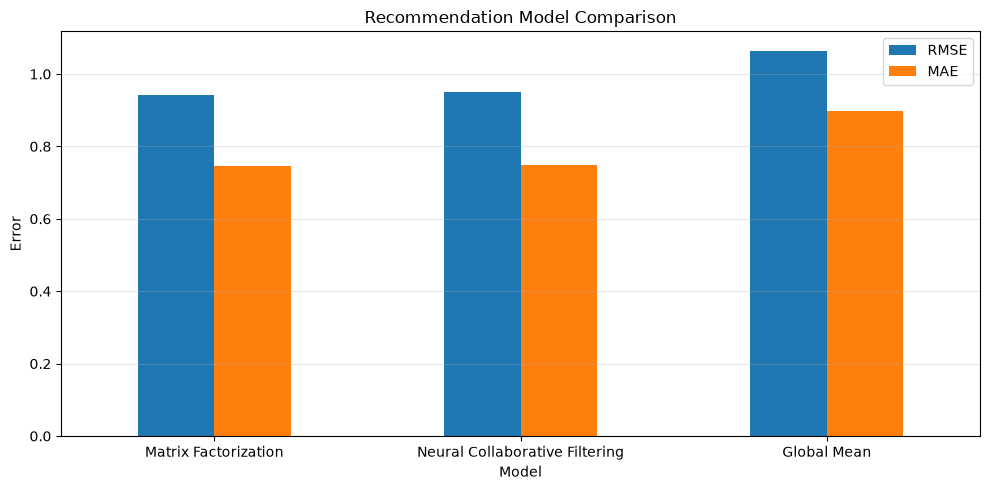

In [21]:
results.set_index("Model")[["RMSE", "MAE"]].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Recommendation Model Comparison")
plt.xlabel("Model")
plt.ylabel("Error")
plt.xticks(rotation=0)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.show()

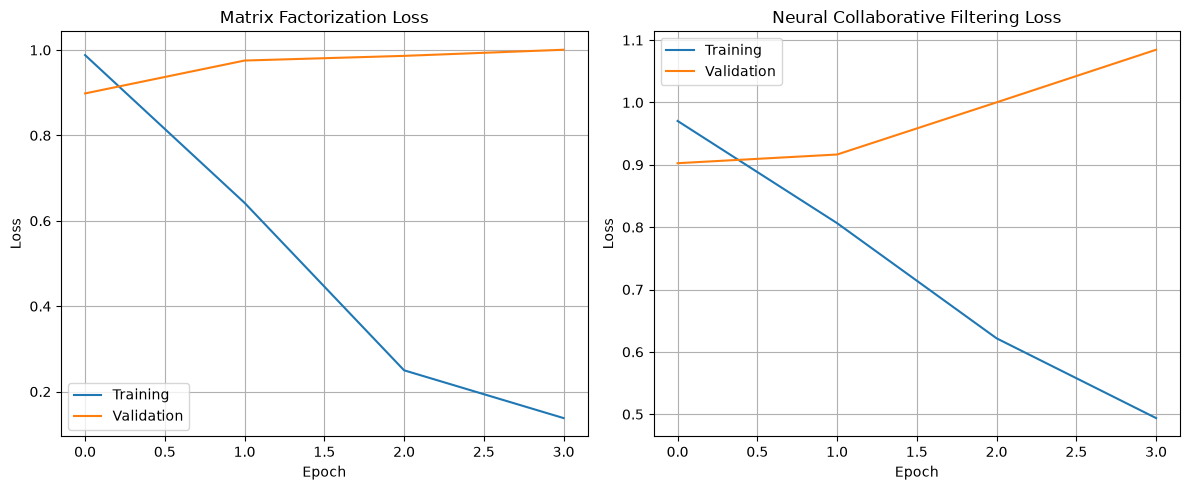

In [22]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.plot(history_mf.history["loss"], label="Training")
plt.plot(history_mf.history["val_loss"], label="Validation")

plt.title("Matrix Factorization Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)

plt.plot(history_ncf.history["loss"], label="Training")
plt.plot(history_ncf.history["val_loss"], label="Validation")

plt.title("Neural Collaborative Filtering Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [24]:
if mf_results["RMSE"] <= ncf_results["RMSE"]:
    best_model = mf_model
    best_model_name = "Matrix Factorization"
else:
    best_model = ncf_model
    best_model_name = "Neural Collaborative Filtering"

print("Selected model:", best_model_name)

if baseline["RMSE"] < min(mf_results["RMSE"], ncf_results["RMSE"]):
    print("Warning: The Global Mean baseline performed better.")

Selected model: Matrix Factorization


In [25]:
movies_df = pd.read_csv(
    "archive/movie_titles.csv",
    header=None,
    names=["raw"],
    sep="\t",
    encoding="latin-1"
)

movies_df[["movie_id", "year", "title"]] = (
    movies_df["raw"].str.split(",", n=2, expand=True)
)

movies_df = movies_df.drop(columns="raw")

movies_df["movie_id"] = movies_df["movie_id"].astype(int)

movies_df.head(10)

,movie_id,year,title
0,1,2003,Dinosaur Planet
1,2,2004,Isle of Man TT 2004 Review
2,3,1997,Character
3,4,1994,Paula Abdul's Get Up & Dance
4,5,2004,The Rise and Fall of ECW
5,6,1997,Sick
6,7,1992,8 Man
7,8,2004,What the #$*! Do We Know!?
8,9,1991,Class of Nuke 'Em High 2
9,10,2001,Fighter


In [26]:
def recommend_movies(user_id, model, top_n=10):

    # Find user's encoded ID
    user_rows = df[df["user_id"] == user_id]

    if user_rows.empty:
        raise ValueError("User not found in the dataset.")

    user_idx = int(user_rows["user_idx"].iloc[0])

    # Movies already seen in training
    rated_movies = set(
        train_df.loc[
            train_df["user_idx"] == user_idx,
            "movie_idx"
        ]
    )

    # Find unrated candidate movies
    all_movies = np.arange(num_movies)

    candidate_movies = np.array([
        movie for movie in all_movies
        if movie not in rated_movies
    ], dtype=np.int32)

    if len(candidate_movies) == 0:
        return pd.DataFrame(
            columns=["movie_id", "title", "predicted_rating"]
        )

    user_array = np.full(
        (len(candidate_movies), 1),
        user_idx,
        dtype=np.int32
    )

    movie_array = candidate_movies.reshape(-1, 1)

    # Predict ratings
    predictions = model.predict(
        {
            "user": user_array,
            "movie": movie_array
        },
        verbose=0
    ).flatten()

    predictions = np.clip(predictions + rating_mean, 1, 5)

    # Convert encoded movie IDs back to original IDs
    recommendations = pd.DataFrame({
        "movie_id": unique_movies.take(candidate_movies),
        "predicted_rating": predictions
    })

    # Join movie titles
    recommendations = recommendations.merge(
        movies_df[["movie_id", "title"]],
        on="movie_id",
        how="left"
    )

    recommendations = recommendations.sort_values(
        "predicted_rating",
        ascending=False
    )

    return recommendations.head(top_n)[
        ["movie_id", "title", "predicted_rating"]
    ].reset_index(drop=True)

In [27]:
user_id = int(train_df["user_id"].iloc[0])

print("Recommendations for user:", user_id)

top_10 = recommend_movies(
    user_id=user_id,
    model=best_model,
    top_n=10
)

top_10

Recommendations for user: 1488844


,movie_id,title,predicted_rating
0,209,Star Trek: Deep Space Nine: Season 5,3.988915
1,13,Lord of the Rings: The Return of the King: Ext...,3.941036
2,223,Chappelle's Show: Season 1,3.900254
3,32,ABC Primetime: Mel Gibson's The Passion of the...,3.897972
4,167,The Chorus,3.839949
5,138,Star Trek: Voyager: Season 1,3.834245
6,215,That '70s Show: Season 1,3.833984
7,85,Elfen Lied,3.828898
8,33,Aqua Teen Hunger Force: Vol. 1,3.825635
9,68,Invader Zim,3.776197


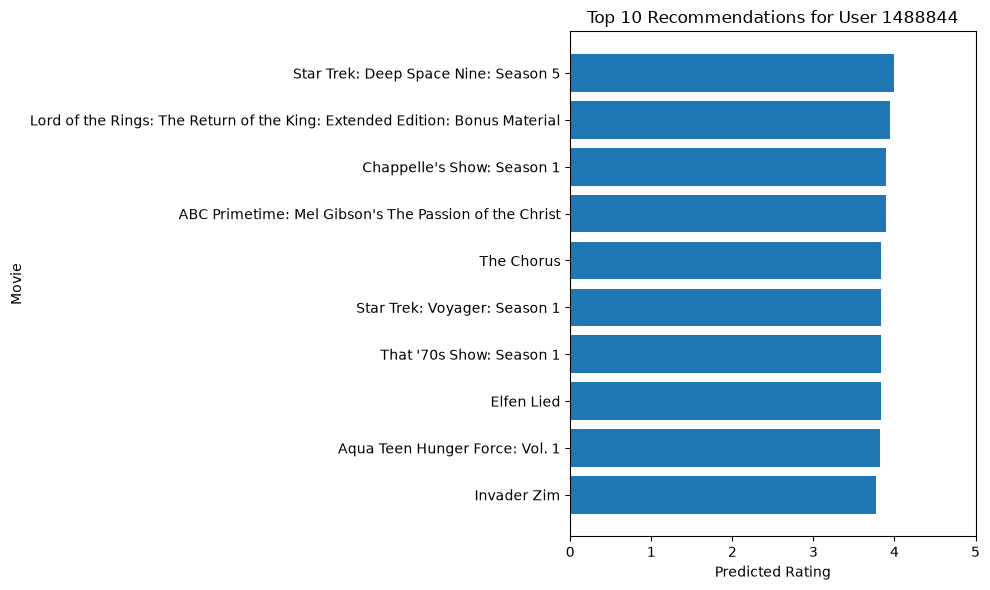

In [28]:
if not top_10.empty:

    plt.figure(figsize=(10, 6))

    plt.barh(
        top_10["title"].fillna("Unknown movie"),
        top_10["predicted_rating"]
    )

    plt.xlabel("Predicted Rating")
    plt.ylabel("Movie")
    plt.title(f"Top 10 Recommendations for User {user_id}")

    plt.xlim(0, 5)
    plt.gca().invert_yaxis()
    plt.tight_layout()

    plt.show()

In [29]:
import json

mf_model.save("matrix_factorization.keras")
ncf_model.save("neural_collaborative_filtering.keras")

# Save user and movie mappings
user_mapping = pd.DataFrame({
    "user_idx": np.arange(num_users),
    "user_id": unique_users
})

movie_mapping = pd.DataFrame({
    "movie_idx": np.arange(num_movies),
    "movie_id": unique_movies
})

user_mapping.to_csv("user_mapping.csv", index=False)
movie_mapping.to_csv("movie_mapping.csv", index=False)

# Save rating mean needed for predictions
with open("model_metadata.json", "w") as file:
    json.dump({
        "rating_mean": float(rating_mean),
        "best_model": best_model_name
    }, file)

print("Models and mappings saved successfully!")

Models and mappings saved successfully!


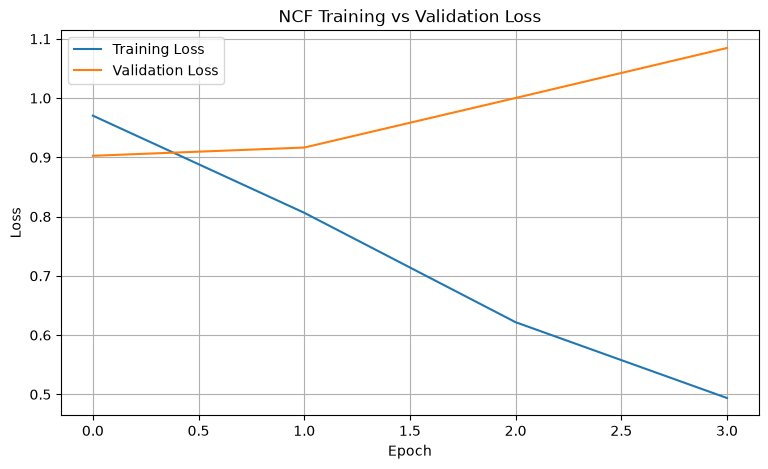

In [30]:
plt.figure(figsize=(9, 5))

plt.plot(
    history_ncf.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_ncf.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("NCF Training vs Validation Loss")
plt.legend()
plt.grid(True)

plt.show()

In [31]:
def build_ncf_model(num_users, num_movies):

    user_input = layers.Input(shape=(1,), name="user")
    movie_input = layers.Input(shape=(1,), name="movie")

    user_embedding = layers.Embedding(
        num_users,
        16,
        embeddings_regularizer=l2(1e-4)
    )(user_input)

    movie_embedding = layers.Embedding(
        num_movies,
        16,
        embeddings_regularizer=l2(1e-4)
    )(movie_input)

    user_vector = layers.Flatten()(user_embedding)
    movie_vector = layers.Flatten()(movie_embedding)

    combined = layers.Concatenate()([
        user_vector,
        movie_vector
    ])

    x = layers.Dense(
        64,
        activation="relu",
        kernel_regularizer=l2(1e-4)
    )(combined)

    x = layers.Dropout(0.4)(x)

    x = layers.Dense(
        32,
        activation="relu",
        kernel_regularizer=l2(1e-4)
    )(x)

    output = layers.Dense(1)(x)

    return Model(
        inputs={
            "user": user_input,
            "movie": movie_input
        },
        outputs=output
    )


ncf_model = build_ncf_model(num_users, num_movies)

ncf_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0003
    ),
    loss="mse",
    metrics=[
        tf.keras.metrics.RootMeanSquaredError(name="rmse")
    ]
)

ncf_model.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ user (InputLayer)   │ (None, 1)         │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ movie (InputLayer)  │ (None, 1)         │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_8         │ (None, 1, 16)     │  1,122,688 │ user[0][0]        │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_9         │ (None, 1, 16)     │      3,600 │ movie[0][0]       │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_8 (Flatten) │ (None, 16)        │          0 │ embedding_8[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_9 (Flatten) │ (None, 16)        │          0 │ embedding_9[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_2       │ (None, 32)        │          0 │ flatten_8[0][0],  │
│ (Concatenate)       │                   │            │ flatten_9[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_8 (Dense)     │ (None, 64)        │      2,112 │ concatenate_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 64)        │          0 │ dense_8[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_9 (Dense)     │ (None, 32)        │      2,080 │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_10 (Dense)    │ (None, 1)         │         33 │ dense_9[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,130,513 (4.31 MB)

 Trainable params: 1,130,513 (4.31 MB)

 Non-trainable params: 0 (0.00 B)

In [33]:
early_stop_ncf = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history_ncf = ncf_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=512,
    callbacks=[early_stop_ncf],
    verbose=1
)

Epoch 1/20
992/992 ━━━━━━━━━━━━━━━━━━━━ 10s 8ms/step - loss: 1.0224 - rmse: 0.9978 - val_loss: 0.9318 - val_rmse: 0.9529
Epoch 2/20
992/992 ━━━━━━━━━━━━━━━━━━━━ 21s 21ms/step - loss: 0.8734 - rmse: 0.9200 - val_loss: 0.9350 - val_rmse: 0.9514
Epoch 3/20
992/992 ━━━━━━━━━━━━━━━━━━━━ 30s 31ms/step - loss: 0.8105 - rmse: 0.8818 - val_loss: 0.9583 - val_rmse: 0.9604


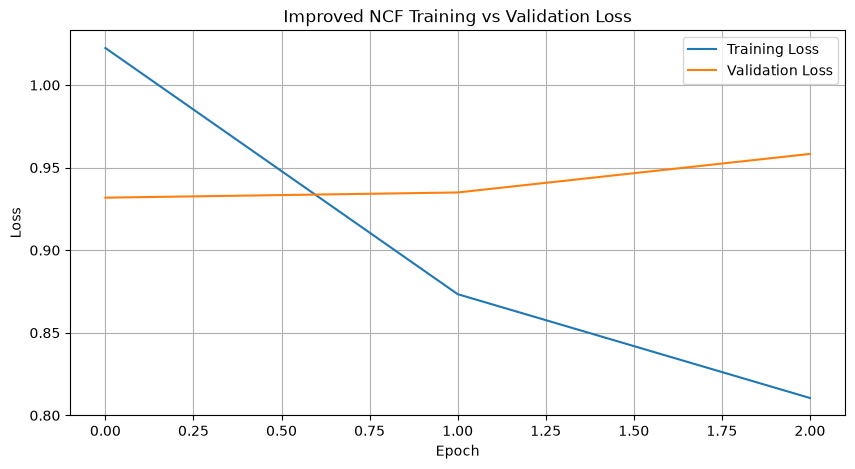

In [34]:
plt.figure(figsize=(10, 5))

plt.plot(
    history_ncf.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_ncf.history["val_loss"],
    label="Validation Loss"
)

plt.title("Improved NCF Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.show()

In [35]:
new_ncf_results = evaluate_model(
    ncf_model,
    "Improved NCF"
)

print("Improved NCF RMSE:", new_ncf_results["RMSE"])
print("Improved NCF MAE:", new_ncf_results["MAE"])

Improved NCF RMSE: 0.9528686831043026
Improved NCF MAE: 0.7492244271343204


In [36]:
best_model = mf_model
best_model_name = "Matrix Factorization"

best_model.save("best_netflix_recommender.keras")

print("Best model:", best_model_name)
print("RMSE:", mf_results["RMSE"])
print("MAE:", mf_results["MAE"])

Best model: Matrix Factorization
RMSE: 0.9431393380490601
MAE: 0.7446017522460264
